# 05 · Modelo multimodal (sexo, espectral, prosodia, texto, contexto)

Un solo modelo con el sexo como variable, en PREGUNTA1, PREGUNTA2 y P1+P2. Desenlaces: **dep** = PHQ-9 ≥ 15 y
**ans** = GAD-7 ≥ 10. Evaluación con CV anidada: externa de 5 pliegues × 5 repeticiones, estratificada por sexo ×
desenlace e igual para todas las configuraciones; interna de 3 pliegues para los hiperparámetros. La prueba final
sellada no se usa.

El cálculo está en `multimodal.py`, que guarda sus salidas en `outputs/mm_*.csv`. Este notebook solo lee esas salidas y
muestra agregados.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = Path("outputs")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
res = pd.read_csv(OUT / "mm_resumen.csv")
uni = res[~res["capa"].str.endswith("-ss")]
elegidas = json.loads((OUT / "mm_elegidas.json").read_text())
CONJ = ["P1", "P2", "P1+P2"]

def tabla(df, valor="auc", de="auc_de", filas="capa"):
    t = df.assign(v=df[valor].map("{:.3f}".format) + (" ± " + df[de].map("{:.3f}".format) if de else ""))
    return t.pivot_table(index=filas, columns=["objetivo", "conjunto"], values="v", aggfunc="first")\
            .reindex(columns=[(o, c) for o in ["dep", "ans"] for c in CONJ])

## 1. Muestra y etiquetas

In [2]:
n = res.groupby("objetivo")[["n", "casos"]].first()
n["prevalencia"] = (n["casos"] / n["n"]).round(3)
n

,n,casos,prevalencia
objetivo,,,
ans,352,104,0.295
dep,352,67,0.190


In [3]:
aud = OUT / "auditoria_etiquetas.csv"
pd.read_csv(aud) if aud.exists() else "sin auditoria_etiquetas.csv"

,tipo,variable,descripcion,n_mujer,N_mujer,pct_mujer,n_hombre,N_hombre,pct_hombre,n_total,pct_total,or_hombre_vs_mujer,p_fisher
0,bandera,a_ceros_phq9_gad7,(a) 0 en PHQ-9 y 0 en GAD-7,6,197,3.045685,15,158,9.493671,21,5.915493,3.339161,0.012549
1,bandera,a_cero_phq9,detalle (a): 0 en PHQ-9,6,197,3.045685,19,158,12.025316,25,7.042254,4.351319,0.001353
2,bandera,a_cero_gad7,detalle (a): 0 en GAD-7,9,197,4.568528,23,158,14.556962,32,9.014085,3.558848,0.001333
3,bandera,a_ceros_phq9_gad7_bdi,"detalle (a): 0 en PHQ-9, GAD-7 y BDI",5,197,2.538071,6,158,3.797468,11,3.098592,1.515789,0.548604
4,bandera,b_plana_37_items,(b) 37 items PHQ-9 + GAD-7 + BDI iguales,5,197,2.538071,6,158,3.797468,11,3.098592,1.515789,0.548604
5,bandera,b_plana_phq9,detalle (b): 9 items PHQ-9 iguales,9,197,4.568528,22,158,13.924051,31,8.732394,3.379085,0.002278
6,bandera,b_plana_gad7,detalle (b): 7 items GAD-7 iguales,22,197,11.167513,29,158,18.354430,51,14.366197,1.788231,0.067442
7,bandera,b_plana_bdi,detalle (b): 21 items BDI iguales,9,197,4.568528,12,158,7.594937,21,5.915493,1.716895,0.262181
8,bandera,c_residuo_abs_z2,(c) |z| > 2 en PHQ-9 ~ SUMABECK,6,197,3.045685,3,158,1.898734,9,2.535211,0.616129,0.736463
9,bandera,c_residuo_bajo,detalle (c): z < -2 (PHQ-9 bajo para su BDI),2,197,1.015228,2,158,1.265823,4,1.126761,1.250000,1.000000


**Lectura.** 352 sujetos de desarrollo: 67 casos de depresión (PHQ-9 ≥ 15) y 104 de ansiedad (GAD-7 ≥ 10). Los casos de depresión son el doble de frecuentes en mujeres (25 % frente a 12 %), así que el sexo solo ya da AUC ≈ 0,60. Los dobles ceros (0 en PHQ-9 y en GAD-7) son más frecuentes en hombres (9,5 % frente a 3,0 %, p = 0,013), lo que es consistente con subreporte; la respuesta plana en los 37 ítems no difiere por sexo.

## 2. Variables del Excel (logit `y ~ variable + sexo`, BH)

In [4]:
ex = OUT / "excel_variables.csv"
ev = pd.read_csv(ex) if ex.exists() else pd.DataFrame()
ev.sort_values([c for c in ["objetivo", "q", "p"] if c in ev.columns]).head(40) if len(ev) else "sin excel_variables.csv"

,muestra,desenlace,variable,termino,N,casos,tipo_x,n_x1,media_x_casos,media_x_no_casos,OR,IC95_inf,IC95_sup,p_wald,gl_variable,p_lr_variable,nota,q_bh
0,completa,dep,edad,edad,355,68,numerica,NaN,16.073529,15.947735,1.193797,0.904352,1.575880,2.111786e-01,2,2.578583e-01,NaN,3.570346e-01
1,completa,dep,edad,edad_faltante,355,68,binaria,73.0,0.250000,0.195122,1.421859,0.754839,2.678298,2.759679e-01,2,2.578583e-01,NaN,3.570346e-01
2,completa,dep,curso,curso,355,68,numerica,NaN,2.558824,2.515679,1.062121,0.790048,1.427890,6.897756e-01,1,6.892822e-01,NaN,7.298282e-01
3,completa,dep,nacionalidad_no1,nacionalidad_no1,355,68,binaria,24.0,0.044118,0.073171,0.607026,0.173519,2.123574,4.346395e-01,1,4.102058e-01,NaN,4.614815e-01
4,completa,dep,generoconforme,generoconforme,355,68,binaria,16.0,0.117647,0.027875,3.734009,1.325628,10.517896,1.265044e-02,1,1.499553e-02,NaN,3.803083e-02
5,completa,dep,identidad_genero,identidad_genero_c2,355,68,binaria,157.0,0.250000,0.487805,0.106400,0.008676,1.304913,7.979548e-02,2,8.648172e-03,NaN,2.594452e-02
6,completa,dep,identidad_genero,identidad_genero_otros,355,68,binaria,16.0,0.117647,0.027875,2.805037,0.954276,8.245241,6.080823e-02,2,8.648172e-03,NaN,2.594452e-02
7,completa,dep,orientacion_sexual,orientacion_sexual_c2,355,68,binaria,52.0,0.220588,0.128920,1.694006,0.837955,3.424595,1.421875e-01,3,3.843667e-01,NaN,4.612401e-01
8,completa,dep,orientacion_sexual,orientacion_sexual_c3,355,68,binaria,11.0,0.044118,0.027875,1.761601,0.441988,7.021086,4.221951e-01,3,3.843667e-01,NaN,4.612401e-01
9,completa,dep,orientacion_sexual,orientacion_sexual_c4,355,68,binaria,19.0,0.088235,0.045296,1.761698,0.619111,5.012956,2.885396e-01,3,3.843667e-01,NaN,4.612401e-01


**Lectura.** Las variables escolares y de consumo son las más asociadas: motivación (OR 0,18 para depresión), satisfacción con la educación, pensar en dejar los estudios, consumo de drogas y disconformidad de género. Son autorreporte del mismo cuestionario que PHQ-9 y GAD-7, y "motivado" se superpone con la anhedonia: sirven como capa de contexto clínico, no como biomarcador.

## 3. Escalas de audio (una escala por familia, cada una con el sexo)

In [5]:
esc = uni[uni["capa"].str.match(r"^(espectral|prosodia):") | (uni["capa"] == "sexo")]
tabla(esc)

objetivo                     dep                                          ans                              
conjunto                      P1             P2          P1+P2             P1             P2          P1+P2
capa                                                                                                       
espectral:glob|rf  0.610 ± 0.061  0.599 ± 0.067  0.609 ± 0.067  0.524 ± 0.048  0.544 ± 0.048  0.524 ± 0.046
espectral:seg|rf   0.591 ± 0.068  0.620 ± 0.038  0.617 ± 0.055  0.531 ± 0.041  0.524 ± 0.044  0.522 ± 0.048
espectral:v10|rf   0.603 ± 0.059  0.655 ± 0.050  0.647 ± 0.044  0.545 ± 0.062  0.564 ± 0.049  0.559 ± 0.049
espectral:v1|rf    0.614 ± 0.068  0.639 ± 0.052  0.640 ± 0.061  0.545 ± 0.055  0.535 ± 0.044  0.537 ± 0.059
espectral:v5|rf    0.619 ± 0.061  0.626 ± 0.051  0.635 ± 0.055  0.565 ± 0.060  0.555 ± 0.053  0.553 ± 0.062
prosodia:glob|rf   0.567 ± 0.093  0.639 ± 0.068  0.606 ± 0.094  0.517 ± 0.073  0.547 ± 0.075  0.522 ± 0.072
prosodia:v10|rf    0.601 ± 0.084  0.656 ± 0.066  0.653 ± 0.085  0.543 ± 0.081  0.620 ± 0.080  0.614 ± 0.076
prosodia:v5|rf     0.582 ± 0.077  0.646 ± 0.081  0.625 ± 0.087  0.544 ± 0.082  0.621 ± 0.086  0.610 ± 0.087
sexo               0.602 ± 0.015  0.602 ± 0.015  0.602 ± 0.015  0.580 ± 0.003  0.580 ± 0.003  0.580 ± 0.003

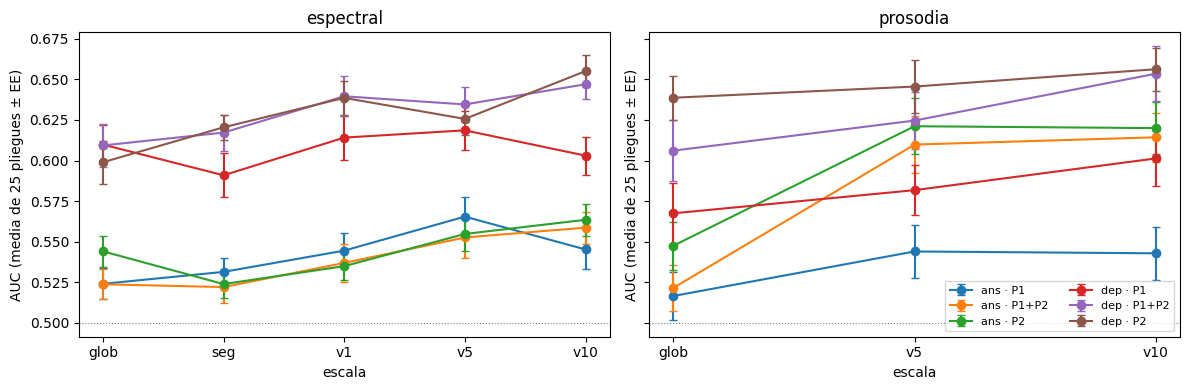

Escalas elegidas para la fusion: {'espectral': 'v10', 'prosodia': 'v10', 'texto': 'texto:qwen|lr'}


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, fam in zip(axes, ["espectral", "prosodia"]):
    d = uni[uni["capa"].str.startswith(fam + ":")].copy()
    d["escala"] = d["capa"].str.extract(r":(\w+)\|")[0]
    for (o, c), g in d.groupby(["objetivo", "conjunto"]):
        ax.errorbar(g["escala"], g["auc"], yerr=g["auc_de"] / np.sqrt(25), marker="o", capsize=3, label=f"{o} · {c}")
    ax.axhline(0.5, color="grey", lw=0.8, ls=":")
    ax.set_title(fam); ax.set_xlabel("escala"); ax.set_ylabel("AUC (media de 25 pliegues ± EE)")
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()
print("Escalas elegidas para la fusion:", elegidas)

**Lectura.** En ambas familias, las ventanas de 10 s son la mejor escala y el audio completo la peor: resumir por ventanas (media y DE) captura algo que el promedio global pierde. Los tramos entre pausas y la ventana de 1 s no mejoran sobre 10 s. La prosodia rinde más que lo espectral, sobre todo en P2. Estas cifras son de un RF con el sexo entre muchas features, que diluye el sexo: sirven para comparar escalas entre sí, no contra el sexo solo (eso está en la sección 5).

## 4. Texto (embeddings, cada uno con el sexo)

In [7]:
tx = uni[uni["capa"].str.startswith("texto:")]
tabla(tx) if len(tx) else "sin embeddings"

objetivo                    dep                                          ans                              
conjunto                     P1             P2          P1+P2             P1             P2          P1+P2
capa                                                                                                      
texto:beto|lr     0.576 ± 0.062  0.573 ± 0.073  0.604 ± 0.072  0.565 ± 0.051  0.506 ± 0.057  0.549 ± 0.052
texto:beto|rfpca  0.607 ± 0.080  0.634 ± 0.084  0.614 ± 0.079  0.582 ± 0.064  0.565 ± 0.069  0.525 ± 0.058
texto:e5|lr       0.559 ± 0.081  0.579 ± 0.073  0.591 ± 0.071  0.598 ± 0.055  0.482 ± 0.060  0.543 ± 0.049
texto:e5|rfpca    0.553 ± 0.090  0.601 ± 0.058  0.568 ± 0.090  0.523 ± 0.058  0.538 ± 0.088  0.521 ± 0.069
texto:qwen|lr     0.601 ± 0.081  0.594 ± 0.074  0.637 ± 0.075  0.586 ± 0.043  0.501 ± 0.067  0.558 ± 0.050
texto:qwen|rfpca  0.592 ± 0.077  0.648 ± 0.053  0.621 ± 0.068  0.596 ± 0.055  0.553 ± 0.068  0.562 ± 0.058

**Lectura.** Qwen3-Embedding con logística es el mejor texto en depresión (0,637 en P1+P2). BETO queda por debajo con los dos modelos. En ansiedad ningún embedding se separa del sexo.

## 5. Contribución de cada conjunto de datos (tabla principal)

Cada fila es un stacking: el modelo de solo sexo más una o más capas. Cada capa da su probabilidad y una logística las
combina. Así el ΔAUC frente al solo sexo mide lo que agrega la capa. Un RF con el sexo metido entre muchas features
diluye la señal del sexo: con datos al azar da menos que el sexo solo.

In [8]:
orden = ["sexo", "fusion:sexo+espectral", "fusion:sexo+prosodia", "fusion:tardia_audio",
         "fusion:sexo+audio_hibrido", "fusion:sexo+texto", "fusion:sexo+contexto", "fusion:tardia_audio+texto",
         "fusion:hibrida_audio+texto", "fusion:tardia_audio+texto+contexto"]
pr = res[res["capa"].isin(orden)]
t = tabla(pr).reindex([o for o in orden if o in set(pr["capa"])])
t

objetivo                                      dep                                          ans                              
conjunto                                       P1             P2          P1+P2             P1             P2          P1+P2
capa                                                                                                                        
sexo                                0.602 ± 0.015  0.602 ± 0.015  0.602 ± 0.015  0.580 ± 0.003  0.580 ± 0.003  0.580 ± 0.003
fusion:sexo+espectral               0.608 ± 0.042  0.655 ± 0.037  0.646 ± 0.037  0.550 ± 0.036  0.569 ± 0.037  0.565 ± 0.033
fusion:sexo+prosodia                0.632 ± 0.068  0.669 ± 0.052  0.669 ± 0.062  0.548 ± 0.046  0.632 ± 0.066  0.629 ± 0.057
fusion:tardia_audio                 0.619 ± 0.062  0.679 ± 0.040  0.667 ± 0.057  0.536 ± 0.052  0.619 ± 0.065  0.612 ± 0.057
fusion:sexo+audio_hibrido           0.630 ± 0.047  0.684 ± 0.038  0.671 ± 0.044  0.545 ± 0.038  0.618 ± 0.045  0.592 ± 0.049
fusion:sexo+texto                   0.620 ± 0.073  0.634 ± 0.054  0.663 ± 0.068  0.603 ± 0.037  0.551 ± 0.052  0.578 ± 0.046
fusion:sexo+contexto                0.752 ± 0.057  0.752 ± 0.057  0.752 ± 0.057  0.672 ± 0.048  0.672 ± 0.048  0.672 ± 0.048
fusion:tardia_audio+texto           0.627 ± 0.075  0.688 ± 0.052  0.690 ± 0.064  0.575 ± 0.047  0.589 ± 0.070  0.596 ± 0.055
fusion:hibrida_audio+texto          0.632 ± 0.066  0.694 ± 0.050  0.682 ± 0.065  0.583 ± 0.038  0.585 ± 0.055  0.585 ± 0.044
fusion:tardia_audio+texto+contexto  0.730 ± 0.070  0.759 ± 0.065  0.762 ± 0.070  0.653 ± 0.052  0.658 ± 0.066  0.663 ± 0.058

In [9]:
d = pr.assign(v=pr["dauc_vs_sexo"].map("{:+.3f}".format) + " (p " + pr["p_vs_sexo"].map("{:.3f}".format) + ")")
d.pivot_table(index="capa", columns=["objetivo", "conjunto"], values="v", aggfunc="first")\
 .reindex(columns=[(o, c) for o in ["dep", "ans"] for c in CONJ]).reindex([o for o in orden if o in set(pr["capa"])])

objetivo                                         dep                                                   ans                                    
conjunto                                          P1                P2             P1+P2                P1                P2             P1+P2
capa                                                                                                                                          
sexo                                +0.000 (p 1.000)  +0.000 (p 1.000)  +0.000 (p 1.000)  +0.000 (p 1.000)  +0.000 (p 1.000)  +0.000 (p 1.000)
fusion:sexo+espectral               +0.006 (p 0.805)  +0.053 (p 0.018)  +0.044 (p 0.027)  -0.029 (p 0.147)  -0.011 (p 0.594)  -0.014 (p 0.421)
fusion:sexo+prosodia                +0.030 (p 0.423)  +0.067 (p 0.021)  +0.067 (p 0.053)  -0.032 (p 0.209)  +0.052 (p 0.163)  +0.049 (p 0.128)
fusion:tardia_audio                 +0.017 (p 0.631)  +0.077 (p 0.002)  +0.065 (p 0.043)  -0.044 (p 0.129)  +0.039 (p 0.277)  +0.033 (p 0.295)
fusion:sexo+audio_hibrido           +0.028 (p 0.283)  +0.082 (p 0.000)  +0.069 (p 0.006)  -0.035 (p 0.093)  +0.038 (p 0.133)  +0.012 (p 0.649)
fusion:sexo+texto                   +0.018 (p 0.645)  +0.032 (p 0.240)  +0.061 (p 0.102)  +0.024 (p 0.253)  -0.028 (p 0.319)  -0.002 (p 0.941)
fusion:sexo+contexto                +0.150 (p 0.000)  +0.150 (p 0.000)  +0.150 (p 0.000)  +0.092 (p 0.002)  +0.092 (p 0.002)  +0.092 (p 0.002)
fusion:tardia_audio+texto           +0.025 (p 0.538)  +0.086 (p 0.005)  +0.088 (p 0.014)  -0.005 (p 0.856)  +0.010 (p 0.798)  +0.017 (p 0.587)
fusion:hibrida_audio+texto          +0.030 (p 0.401)  +0.092 (p 0.002)  +0.080 (p 0.026)  +0.003 (p 0.884)  +0.005 (p 0.864)  +0.006 (p 0.814)
fusion:tardia_audio+texto+contexto  +0.128 (p 0.002)  +0.157 (p 0.000)  +0.160 (p 0.000)  +0.073 (p 0.016)  +0.078 (p 0.038)  +0.083 (p 0.016)

ΔAUC respecto del modelo de solo sexo, con p de la prueba t corregida de Nadeau–Bengio sobre los 25 pliegues pareados.

**Lectura.** Depresión: sexo + espectral + prosodia + texto da 0,690 en P1+P2 (+0,088 sobre el sexo, p = 0,014) y 0,688 en P2. Audio y texto suman: cada uno solo agrega +0,06. Ansiedad: ninguna capa de voz o texto supera con claridad al sexo; lo mejor es la prosodia (+0,05, p ≈ 0,13). P1 casi no agrega en nada. El contexto del Excel es lo más fuerte (0,75 en depresión) y sumado a audio + texto llega a 0,76. La fusión híbrida no supera a la tardía.

## 5b. ¿Sobreexplica el sexo? Ramas con y sin el sexo como predictor

En la versión principal, cada rama (espectral, prosodia, texto, contexto) lleva el sexo como una variable más y además
hay una rama de solo sexo. En la versión "ramas sin sexo", las ramas no reciben el sexo como predictor: solo lo usan
para recortar los extremos por sexo, y el sexo entra únicamente como rama propia. La última fila no tiene rama de sexo.

In [10]:
pares = [("fusion:sexo+espectral", "fusion-ss:sexo+espectral"), ("fusion:sexo+prosodia", "fusion-ss:sexo+prosodia"),
         ("fusion:tardia_audio", "fusion-ss:tardia_audio"), ("fusion:sexo+texto", "fusion-ss:sexo+texto"),
         ("fusion:tardia_audio+texto", "fusion-ss:tardia_audio+texto"),
         ("fusion:hibrida_audio+texto", "fusion-ss:hibrida_audio+texto"),
         ("fusion:tardia_audio+texto+contexto", "fusion-ss:tardia_audio+texto+contexto"),
         ("-", "fusion-ss:audio+texto_sin_rama_sexo")]
filas = []
for con, sin in pares:
    for (o, c), g in res[res["conjunto"].isin(CONJ)].groupby(["objetivo", "conjunto"]):
        a = g.set_index("capa")
        f = {"modelo": sin.replace("fusion-ss:", ""), "objetivo": o, "conjunto": c,
             "con sexo en ramas": a["auc"].get(con, np.nan), "ramas sin sexo": a["auc"].get(sin, np.nan),
             "sin sexo · mujer": a["auc_mujer"].get(sin, np.nan), "sin sexo · hombre": a["auc_hombre"].get(sin, np.nan),
             "sin sexo · p vs solo sexo": a["p_vs_sexo"].get(sin, np.nan)}
        filas.append(f)
ss = pd.DataFrame(filas)
ss[ss["conjunto"] == "P1+P2"].set_index(["objetivo", "modelo"]).drop(columns="conjunto").round(3)

,,con sexo en ramas,ramas sin sexo,sin sexo · mujer,sin sexo · hombre,sin sexo · p vs solo sexo
objetivo,modelo,,,,,
ans,sexo+espectral,0.565,0.568,0.479,0.484,0.539
dep,sexo+espectral,0.646,0.646,0.587,0.521,0.042
ans,sexo+prosodia,0.629,0.615,0.531,0.659,0.306
dep,sexo+prosodia,0.669,0.676,0.632,0.602,0.032
ans,tardia_audio,0.612,0.608,0.527,0.632,0.363
dep,tardia_audio,0.667,0.670,0.627,0.571,0.039
ans,sexo+texto,0.578,0.571,0.541,0.494,0.742
dep,sexo+texto,0.663,0.662,0.584,0.631,0.107
ans,tardia_audio+texto,0.596,0.595,0.544,0.574,0.601


In [11]:
ss.pivot_table(index="modelo", columns=["objetivo", "conjunto"], values="ramas sin sexo")\
  .reindex(columns=[(o, c) for o in ["dep", "ans"] for c in CONJ]).round(3)

objetivo                       dep                  ans              
conjunto                        P1     P2  P1+P2     P1     P2  P1+P2
modelo                                                               
audio+texto_sin_rama_sexo    0.616  0.687  0.690  0.542  0.568  0.579
hibrida_audio+texto          0.632  0.693  0.686  0.578  0.580  0.588
sexo+espectral               0.613  0.658  0.646  0.553  0.572  0.568
sexo+prosodia                0.629  0.672  0.676  0.541  0.623  0.615
sexo+texto                   0.619  0.634  0.662  0.603  0.546  0.571
tardia_audio                 0.622  0.684  0.670  0.526  0.612  0.608
tardia_audio+texto           0.631  0.688  0.693  0.566  0.584  0.595
tardia_audio+texto+contexto  0.732  0.759  0.763  0.647  0.653  0.663

**Lectura.** Sacar el sexo de las ramas no cambia nada (depresión 0,693 frente a 0,690; dentro de cada sexo 0,644 y 0,655), y sin ninguna rama de sexo el modelo da lo mismo (0,690). El sexo no está sobreexplicando: la ganancia viene de la voz y el texto. La versión con ramas sin sexo y el sexo como rama propia es la más limpia.

## 6. AUC dentro de cada sexo y métricas con umbral (P1+P2)

In [12]:
cols = ["auc", "auc_mujer", "auc_hombre", "bal_acc", "sens", "esp"]
pr[pr["conjunto"] == "P1+P2"].set_index(["objetivo", "capa"])[cols].round(3)

auc  auc_mujer  auc_hombre  bal_acc   sens    esp
objetivo capa                                                                                   
dep      sexo                                0.602      0.493       0.479    0.602  0.716  0.488
ans      sexo                                0.580      0.494       0.498    0.580  0.663  0.496
dep      fusion:sexo+espectral               0.646      0.585       0.525    0.615  0.683  0.547
         fusion:sexo+prosodia                0.669      0.632       0.586    0.617  0.656  0.577
         fusion:sexo+audio_hibrido           0.671      0.631       0.529    0.630  0.680  0.580
         fusion:tardia_audio                 0.667      0.629       0.558    0.618  0.663  0.574
         fusion:sexo+texto                   0.663      0.584       0.626    0.607  0.605  0.608
         fusion:tardia_audio+texto           0.690      0.645       0.645    0.656  0.690  0.622
         fusion:hibrida_audio+texto          0.682      0.635       0.629    0.645  0.669  0.621
         fusion:sexo+contexto                0.752      0.749       0.638    0.712  0.705  0.719
         fusion:tardia_audio+texto+contexto  0.762      0.767       0.654    0.708  0.714  0.702
ans      fusion:sexo+espectral               0.565      0.484       0.474    0.566  0.621  0.511
         fusion:sexo+prosodia                0.629      0.539       0.668    0.589  0.629  0.548
         fusion:sexo+audio_hibrido           0.592      0.513       0.565    0.578  0.621  0.535
         fusion:tardia_audio                 0.612      0.529       0.640    0.578  0.612  0.544
         fusion:sexo+texto                   0.578      0.541       0.499    0.558  0.569  0.547
         fusion:tardia_audio+texto           0.596      0.546       0.583    0.561  0.567  0.555
         fusion:hibrida_audio+texto          0.585      0.539       0.530    0.563  0.573  0.553
         fusion:sexo+contexto                0.672      0.660       0.612    0.620  0.585  0.655
         fusion:tardia_audio+texto+contexto  0.663      0.649       0.625    0.607  0.604  0.610

**Lectura.** Dentro de un mismo sexo el sexo no puede discriminar (solo sexo ≈ 0,49), así que estos AUC miden la voz y el texto. En depresión, audio + texto da 0,645 en mujeres y en hombres. En ansiedad la prosodia funciona sobre todo en hombres (0,668) y casi nada en mujeres (0,539). Con umbral 0,5, la exactitud balanceada de audio + texto en depresión es 0,656 (sensibilidad 0,69, especificidad 0,62).

## 7. Sensibilidad (P1+P2)

In [13]:
se = OUT / "mm_sensibilidad.csv"
if se.exists():
    s = pd.read_csv(se)
    s = s[s["capa"].str.startswith(("sexo", "fusion:"))]
    display(s.pivot_table(index="capa", columns=["muestra", "objetivo"], values="auc").round(3))
    display(s.groupby(["muestra", "objetivo"])[["n", "casos"]].first())

muestra                    cortes_alternativos        sin_banderas        sin_ceros        solo_texto_humano       
objetivo                                 dep10   dep8          ans    dep       ans    dep               ans    dep
capa                                                                                                               
fusion:hibrida_audio+texto               0.665  0.680        0.552  0.691     0.557  0.663             0.586  0.681
fusion:sexo+audio_hibrido                0.650  0.680        0.593  0.673     0.599  0.663             0.589  0.639
fusion:sexo+espectral                    0.625  0.639        0.551  0.637     0.555  0.632             0.577  0.615
fusion:sexo+prosodia                     0.675  0.711        0.640  0.678     0.622  0.662             0.600  0.656
fusion:sexo+texto                        0.655  0.641        0.536  0.645     0.522  0.630             0.587  0.675
fusion:tardia_audio                      0.665  0.704        0.625  0.674     0.606  0.658             0.588  0.643
fusion:tardia_audio+texto                0.676  0.700        0.589  0.697     0.572  0.667             0.585  0.686
sexo                                     0.619  0.612        0.570  0.596     0.570  0.593             0.578  0.587

n  casos
muestra             objetivo            
cortes_alternativos dep10     352    138
                    dep8      352    125
sin_banderas        ans       318     98
                    dep       318     61
sin_ceros           ans       331    104
                    dep       331     67
solo_texto_humano   ans       312     95
                    dep       312     62

**Lectura.** El resultado de depresión se mantiene en todas las variantes (0,667–0,700): sin dobles ceros, sin banderas de inconsistencia, solo con transcripciones humanas y con los cortes PHQ-9 ≥ 10 y PHQ-8 ≥ 10. Con PHQ-8 ≥ 10 la prosodia sola llega a 0,711. En ansiedad, al sacar los dobles ceros o las banderas, la prosodia sí supera al sexo (p = 0,026 y 0,041).

## 8. ¿Qué síntomas capta cada capa? (Spearman con cada ítem, P1+P2)

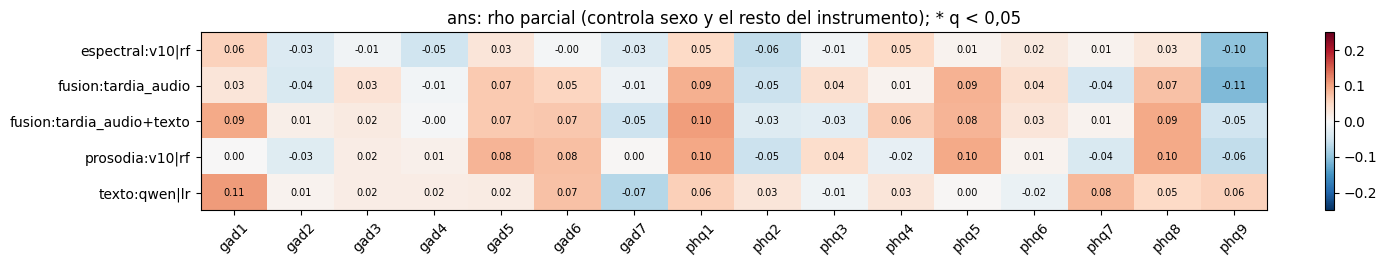

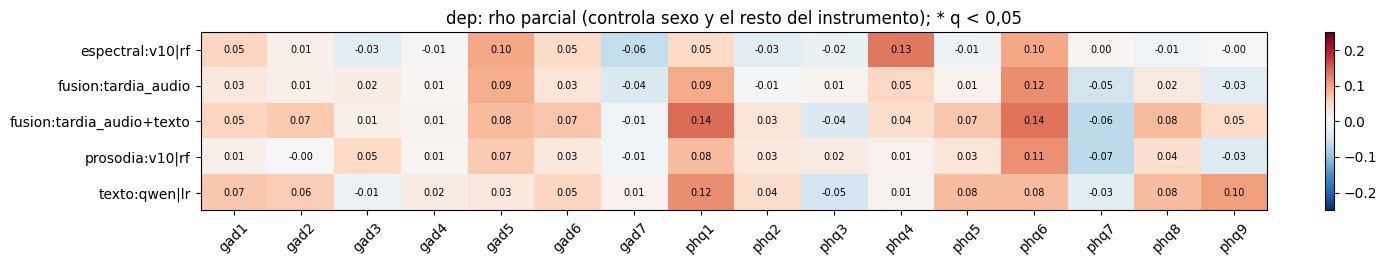

In [14]:
it = pd.read_csv(OUT / "mm_items.csv")
for obj, g in it.groupby("objetivo"):
    m = g.pivot_table(index="capa", columns="item", values="rho_parcial")
    q = g.pivot_table(index="capa", columns="item", values="q_parcial")
    fig, ax = plt.subplots(figsize=(14, 0.5 + 0.45 * len(m)))
    im = ax.imshow(m.to_numpy(), cmap="RdBu_r", vmin=-0.25, vmax=0.25, aspect="auto")
    ax.set_xticks(range(m.shape[1]), m.columns, rotation=45); ax.set_yticks(range(len(m)), m.index)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m.iat[i, j]:.2f}" + ("*" if q.iat[i, j] < 0.05 else ""), ha="center", va="center", fontsize=7)
    ax.set_title(f"{obj}: rho parcial (controla sexo y el resto del instrumento); * q < 0,05")
    plt.colorbar(im, ax=ax, fraction=0.02); plt.tight_layout(); plt.show()

**Lectura.** Crudas, las probabilidades correlacionan 0,25–0,30 con casi todos los ítems, porque siguen al puntaje total. Controlando por el resto del instrumento y el sexo, las correlaciones son chicas (|ρ| ≤ 0,14) y ninguna pasa q < 0,05; las más altas son la anhedonia (phq1) y sentirse un fracaso (phq6). No aparece un ítem propio de la voz.

## 9. Test de permutación (etiquetas permutadas dentro del sexo, P1+P2)

Las etiquetas se barajan dentro de cada sexo, así que el nulo conserva la asociación sexo–desenlace: el test pregunta si
las ramas agregan algo sobre el sexo. Se usan 100 permutaciones (p mínimo ≈ 0,01), con los hiperparámetros modales de
cada rama y una CV simple de 5 pliegues. El AUC observado se calcula igual que el nulo, así que puede diferir del de la
CV anidada.

In [15]:
pe = OUT / "mm_permutacion.csv"
pd.read_csv(pe).round(3) if pe.exists() else "sin permutaciones"

,objetivo,conjunto,modelo,auc_obs,auc_solo_sexo,nulo_media,nulo_p95,p,n_perm
0,dep,P1+P2,sexo+audio (tardia),0.623,0.597,0.598,0.641,0.188,100
1,dep,P1+P2,sexo+texto,0.684,0.597,0.589,0.647,0.010,100
2,dep,P1+P2,sexo+audio+texto (tardia),0.684,0.597,0.588,0.640,0.010,100
3,ans,P1+P2,sexo+audio (tardia),0.659,0.578,0.572,0.607,0.010,100
4,ans,P1+P2,sexo+texto,0.573,0.578,0.561,0.614,0.317,100
5,ans,P1+P2,sexo+audio+texto (tardia),0.640,0.578,0.559,0.609,0.020,100
6,dep,P1+P2,sexo+audio+texto (tardia) [ramas sin sexo],0.695,0.597,0.589,0.638,0.010,100
7,ans,P1+P2,sexo+audio+texto (tardia) [ramas sin sexo],0.625,0.578,0.559,0.614,0.040,100


**Lectura.** Depresión: texto y audio + texto superan al nulo que conserva la asociación sexo–desenlace (p = 0,010, también con ramas sin sexo); el audio solo no (p = 0,19). Ansiedad: en esta partición única audio y audio + texto superan al nulo (p = 0,010–0,040), pero en la CV anidada de 25 pliegues no; queda no concluyente.

## 10. Resumen

**Resumen.**

- Depresión (PHQ-9 ≥ 15): voz + texto agregan ≈ +0,09 de AUC sobre el sexo (0,69), con el mismo rendimiento dentro de mujeres y de hombres, robusto a las sensibilidades y a sacar el sexo de las ramas.
- Ansiedad (GAD-7 ≥ 10): no concluyente; la prosodia en hombres es lo más prometedor.
- La mejor escala es la ventana de 10 s; el mejor texto es Qwen3-Embedding; P2 concentra la señal.
- La escala y el texto se eligieron con estos mismos datos: la cifra que confirma es la de la prueba final sellada, con un único modelo fijado antes de abrirla.